# Week 12 — Data Visualization with Matplotlib
**Muhammad Mirza Apriansyah**

**Learning outcomes**
CPMK 3. Able to process and analyze data using existing software packages.

**Instructions:** Run the code cells in order. Read the explanations and complete the independent exercises before reading the answer key.

`matplotlib.pyplot` `plt.subplots()` `Figure` `Axes` `ax.plot()` `marker` `linestyle` `legend()` `pandas` `DatetimeIndex` `mdates` `annotate()` `ax.bar()` `ax.hist()` `ax.boxplot()` `ax.scatter()` `ax.errorbar()` `plt.style.context()` `fig.savefig()` `dpi` `bbox_inches`

## Table of Contents

1. Introduction to Matplotlib
2. Plotting Time-Series Data
3. Statistical Visualization
4. Saving Figures
5. Independent Student Exercises
6. Meeting Summary and Self-Assessment
7. Google Colab

In [3]:
# Installation (jalankan sekali jika paket belum tersedia)
# %pip install matplotlib numpy pandas

In [1]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path

print("Matplotlib:", matplotlib.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

Matplotlib is building the font cache; this may take a moment.


Matplotlib: 3.11.0
NumPy: 2.4.6
Pandas: 3.0.3


---
## 1. Introduction to Matplotlib

### 1.1 Understanding Matplotlib, Figure, and Axes

**Matplotlib** merupakan pustaka Python untuk membuat grafik. `pyplot` biasanya diimpor sebagai `plt`. Dalam contoh berikut, **`Figure`** adalah keseluruhan gambar, sedangkan **`Axes`** adalah area tempat data digambarkan.

`plt.subplots()` membuat keduanya sekaligus. Gunakan metode `ax` untuk mengatur isi grafik.

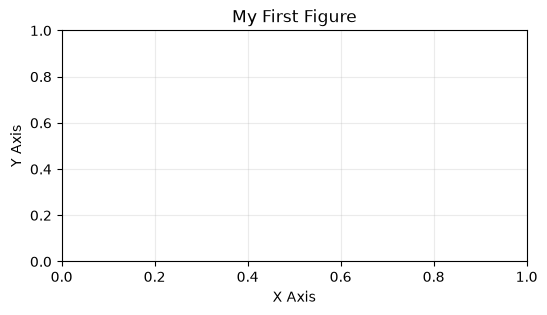

In [34]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.set_title("My First Figure")
ax.set_xlabel("X Axis")
ax.set_ylabel("Y Axis")
ax.grid(alpha=0.25)
plt.show()

Kode ini menggunakan **Matplotlib** untuk membuat grafik berukuran 6 × 3 inci. `set_title()` mengatur judul, `set_xlabel()` dan `set_ylabel()` memberi nama sumbu, `grid()` menambahkan garis kisi, dan `plt.show()` menampilkan grafik.

### 1.2 Creating a Simple Line Plot

**Line plot** menghubungkan titik-titik data dengan garis. Grafik ini cocok untuk menampilkan urutan pengamatan, seperti perubahan nilai dari minggu ke minggu. Sumbu X menunjukkan minggu, sedangkan sumbu Y menunjukkan nilai.

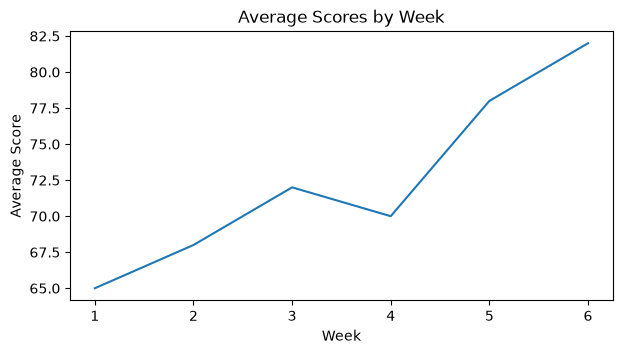

In [3]:
weeks = np.array([1, 2, 3, 4, 5, 6])
average_scores = np.array([65, 68, 72, 70, 78, 82])

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(weeks, average_scores)
ax.set_title("Average Scores by Week")
ax.set_xlabel("Week")
ax.set_ylabel("Average Score")
ax.set_xticks(weeks)
plt.show()

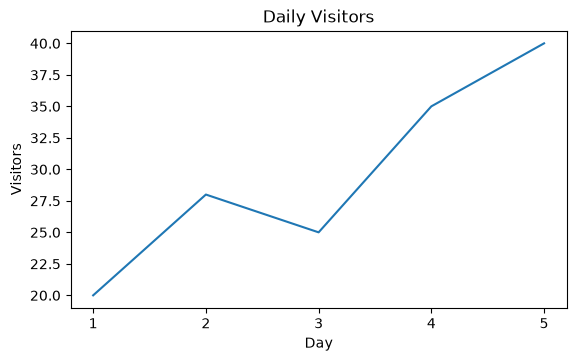

In [47]:
weeks = np.array([1, 2, 3, 4, 5])
average_scores = np.array([20, 28, 25, 35, 40])

fig, ax = plt.subplots(figsize=(6.4, 3.6))
ax.plot(weeks, average_scores)
ax.set_title("Daily Visitors")
ax.set_xlabel("Day")
ax.set_ylabel("Visitors")
ax.set_xticks(weeks)
plt.show()

### 1.3 Customizing Lines, Markers, and Labels

Tampilan grafik bisa diperjelas melalui `color`, `marker`, `linestyle`, dan `label`.

- `marker="o"`: titik pengamatan berbentuk lingkaran.
- `linestyle="--"`: garis putus-putus.
- `ax.legend()`: menampilkan keterangan setiap garis.
- `ax.grid()`: membantu membaca nilai pada sumbu.

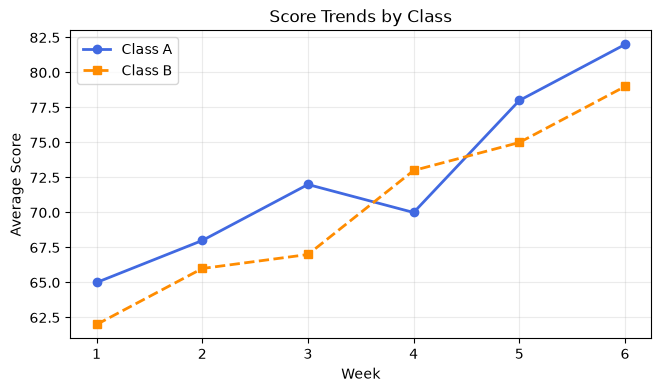

In [35]:
class_a = np.array([65, 68, 72, 70, 78, 82])
class_b = np.array([62, 66, 67, 73, 75, 79])

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(weeks, class_a, color="royalblue", marker="o", linewidth=2, label="Class A")
ax.plot(weeks, class_b, color="darkorange", marker="s", linestyle="--", linewidth=2, label="Class B")
#ax set bisa digabung
ax.set(title="Score Trends by Class", xlabel="Week", ylabel="Average Score")
ax.set_xticks(weeks)
ax.legend()
ax.grid(alpha=0.25)
plt.show()

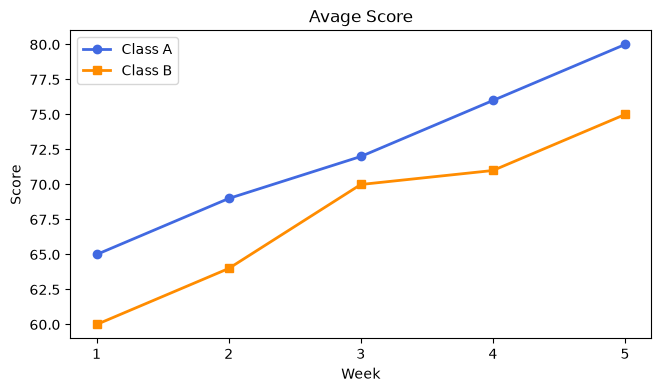

In [45]:
weeks = np.array([1, 2, 3, 4, 5])   
class_a = np.array([65, 69, 72, 76, 80])
class_b = np.array([60, 64, 70, 71, 75])

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(weeks, class_a, color="royalblue", marker="o", linewidth=2, label="Class A")
ax.plot(weeks, class_b, color="darkorange", marker="s", linewidth=2, label="Class B")
#ax set bisa digabung
ax.set(title="Avage Score", xlabel="Week", ylabel="Score")
ax.set_xticks(weeks)
ax.legend()
plt.show()

### 1.4 Creating Multiple Subplots

Jika ingin membandingkan dua grafik tanpa menumpuk seluruh garis, gunakan `plt.subplots(1, 2)`. Artinya, **satu baris** berisi dua grafik. `axes[0]` mengatur grafik kiri dan `axes[1]` mengatur grafik kanan.

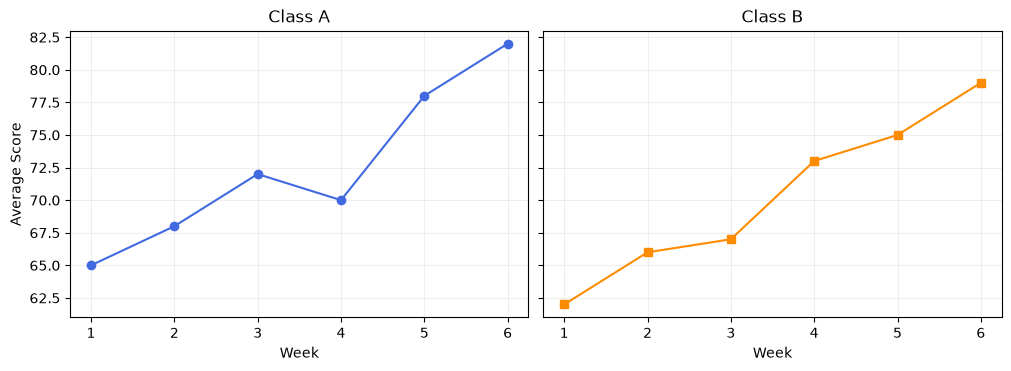

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True, layout="constrained")
axes[0].plot(weeks, class_a, marker="o", color="royalblue")
axes[0].set(title="Class A", xlabel="Week", ylabel="Average Score")

axes[1].plot(weeks, class_b, marker="s", color="darkorange")
axes[1].set(title="Class B", xlabel="Week")
for ax in axes:
    ax.set_xticks(weeks)
    ax.grid(alpha=0.2)
plt.show()

---
## 2. Plotting Time-Series Data

### 2.1 Preparing Dates and Observations

**Time series** adalah data yang dicatat menurut waktu. Tanggal sebaiknya disimpan dalam format yang dapat dikenali Python sebagai tanggal, misalnya memakai `pd.date_range()`.

Contoh berikut menggunakan **curah hujan dan suhu bulanan simulasi** dari dua variabel. Angka-angka ini hanya untuk latihan.

In [6]:
dates = pd.date_range(start="2026-01-01", periods=12, freq="MS")
rainfall = np.array([245, 218, 230, 275, 310, 185, 145, 125, 165, 235, 290, 265])
temperature = np.array([27.5, 27.8, 28.0, 28.2, 28.1, 28.6, 28.8, 29.0, 28.9, 28.4, 28.0, 27.7])
# dates menjadi index
weather = pd.DataFrame({"Rainfall_mm": rainfall, "Temperature_C": temperature}, index=dates)
weather.index.name = "Date"

print("\nIndex type:", type(weather.index).__name__)
print(weather)


Index type: DatetimeIndex
            Rainfall_mm  Temperature_C
Date                                  
2026-01-01          245           27.5
2026-02-01          218           27.8
2026-03-01          230           28.0
2026-04-01          275           28.2
2026-05-01          310           28.1
2026-06-01          185           28.6
2026-07-01          145           28.8
2026-08-01          125           29.0
2026-09-01          165           28.9
2026-10-01          235           28.4
2026-11-01          290           28.0
2026-12-01          265           27.7


### 2.2 Plotting a Time Series

Gunakan tanggal sebagai sumbu X dan nilai pengamatan sebagai sumbu Y. `MonthLocator` dan `DateFormatter` mengatur posisi serta bentuk label tanggal agar lebih mudah dibaca.

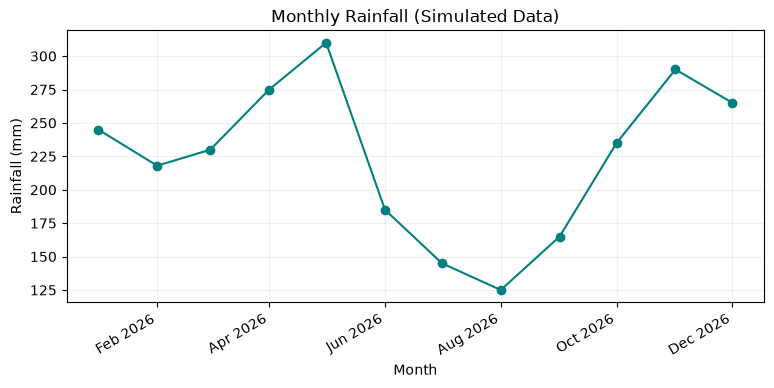

In [7]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(weather.index, weather["Rainfall_mm"], marker="o", color="teal")
ax.set(title="Monthly Rainfall (Simulated Data)", xlabel="Month", ylabel="Rainfall (mm)")

ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))

ax.grid(alpha=0.2)
fig.autofmt_xdate()
plt.show()

Kode ini mengatur tampilan tanggal pada sumbu X. `MonthLocator(interval=2)` menampilkan interval setiap 2 bulan, `DateFormatter("%b %Y")` mengubah format menjadi bulan dan tahun, sedangkan `fig.autofmt_xdate()` merapikan posisi label tanggal agar tidak bertumpuk dalam hal ini miring.

### 2.3 Selecting a Specific Time Period

Kadang kita hanya ingin melihat sebagian periode. Dengan indeks tanggal pada `DataFrame`, `weather.loc["2026-04":"2026-09"]` mengambil data April sampai September 2026.

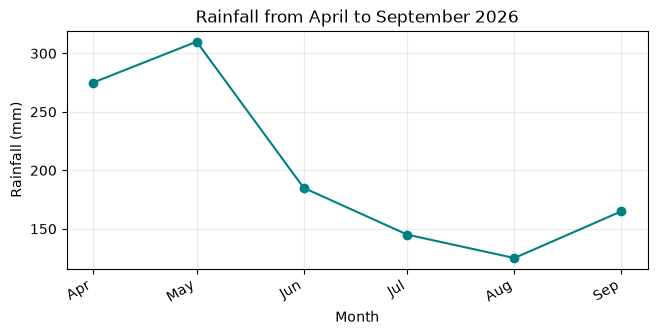

In [8]:
selected_period = weather.loc["2026-04":"2026-09"]

fig, ax = plt.subplots(figsize=(7.5, 3.5))
# disini letak selected period nya
ax.plot(selected_period.index, selected_period["Rainfall_mm"], marker="o", color="teal")
ax.set(title="Rainfall from April to September 2026", xlabel="Month", ylabel="Rainfall (mm)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.grid(alpha=0.25)

fig.autofmt_xdate()
plt.show()

### 2.4 Comparing Time Series with Different Units

Curah hujan (mm) dan suhu (°C) memiliki **satuan dan skala berbeda**. Dua *subplot* terpisah lebih mudah ditafsirkan dibanding memaksakan kedua variabel pada satu sumbu Y.

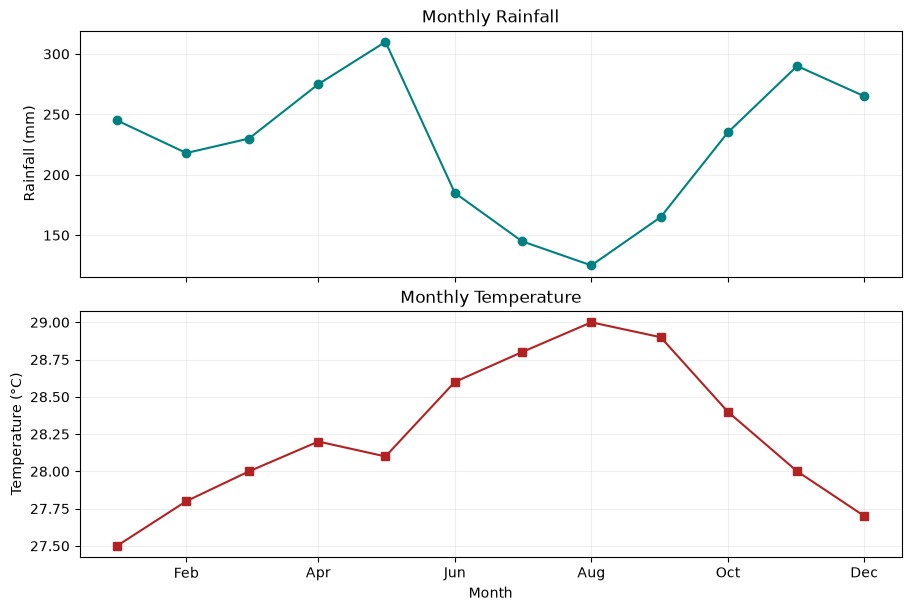

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True, layout="constrained")
axes[0].plot(weather.index, weather["Rainfall_mm"], marker="o", color="teal")
axes[0].set(title="Monthly Rainfall", ylabel="Rainfall (mm)")

axes[1].plot(weather.index, weather["Temperature_C"], marker="s", color="firebrick")
axes[1].set(title="Monthly Temperature", xlabel="Month", ylabel="Temperature (°C)")

axes[1].xaxis.set_major_locator(mdates.MonthLocator(interval=2))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b"))
for ax in axes:
    ax.grid(alpha=0.2)
plt.show()

### 2.5 Annotating Important Observations

`ax.annotate()` menambahkan catatan pada titik tertentu. Contoh berikut menandai bulan dengan curah hujan tertinggi

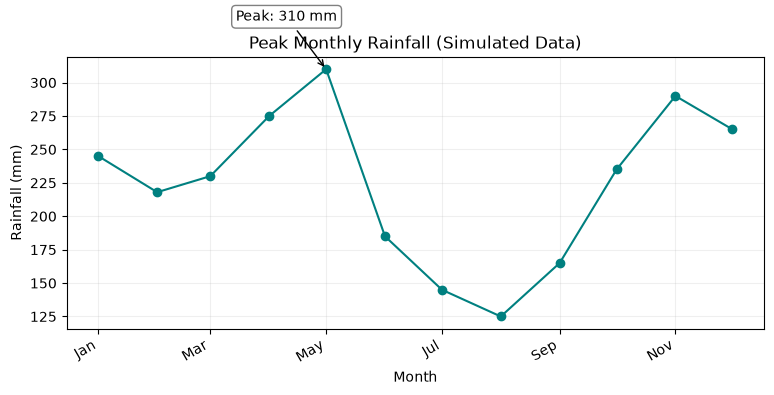

In [10]:
peak_date = weather["Rainfall_mm"].idxmax()
peak_value = weather["Rainfall_mm"].max()

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(weather.index, weather["Rainfall_mm"], marker="o", color="teal")
ax.annotate(f"Peak: {peak_value} mm",
            xy=(peak_date, peak_value), xytext=(-65, 35),
            textcoords="offset points",
            arrowprops={"arrowstyle": "->", "color": "black"},
            bbox={"boxstyle": "round,pad=0.3", "fc": "white", "ec": "gray"})
ax.set(title="Peak Monthly Rainfall (Simulated Data)", xlabel="Month", ylabel="Rainfall (mm)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.grid(alpha=0.2)
fig.autofmt_xdate()
plt.show()

Kode mencari **curah hujan tertinggi** menggunakan `idxmax()` untuk tanggal dan `max()` untuk nilainya. `ax.annotate()` menambahkan keterangan puncak curah hujan beserta panah dan kotak teks. Kode mengatur anotasi pada grafik. `f"Peak: {peak_value} mm"` menampilkan nilai tertinggi, `xy` menentukan posisi titik, `xytext` mengatur posisi teks, `textcoords` menentukan satuan jarak, `arrowprops` mengatur panah, dan `bbox` memberikan kotak latar pada teks.

### 2.6 Using Twin Axes (Optional)

`ax.twinx()` membuat sumbu Y kedua di sisi kanan. Fitur ini berguna ketika dua variabel memiliki kesamaan waktu tetapi berbeda Y. **Hati-hati:** skala yang berbeda. Untuk perbandingan utama bisa menggunakan dua *subplot* sering.

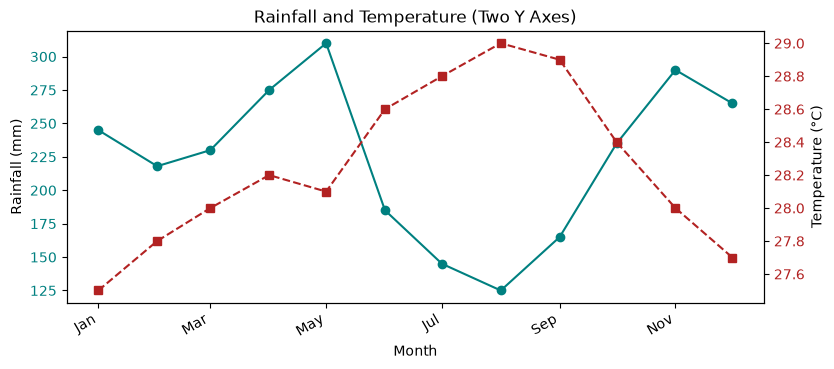

In [11]:
fig, ax1 = plt.subplots(figsize=(9, 4))

ax2 = ax1.twinx()

ax1.plot(weather.index, weather["Rainfall_mm"], color="teal", marker="o", label="Rainfall")
ax2.plot(weather.index, weather["Temperature_C"], color="firebrick", marker="s", linestyle="--", label="Temperature")

ax1.set(title="Rainfall and Temperature (Two Y Axes)", xlabel="Month", ylabel="Rainfall (mm)")
ax2.set_ylabel("Temperature (°C)")

ax1.tick_params(axis="y", labelcolor="teal")
ax2.tick_params(axis="y", labelcolor="firebrick")

ax1.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
fig.autofmt_xdate()
plt.show()

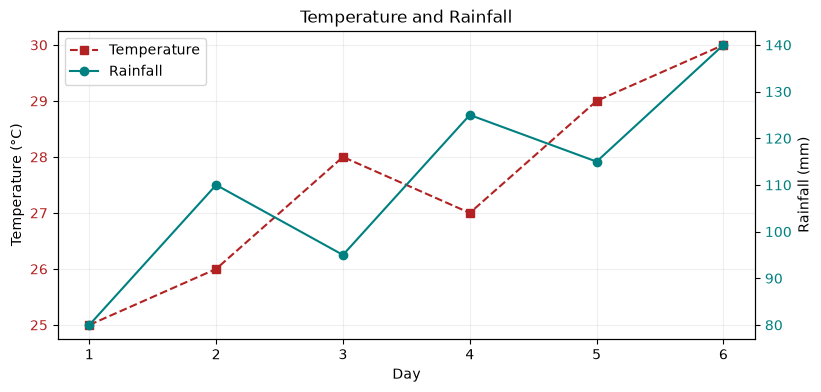

In [54]:
day = np.array([1, 2, 3, 4, 5, 6])
temperature = np.array([25, 26, 28, 27, 29, 30])
rainfall = np.array([80, 110, 95, 125, 115, 140])

fig, ax1 = plt.subplots(figsize=(9, 4))
ax2 = ax1.twinx()

# ax1 (kiri): Temperature | ax2 (kanan): Rainfall
line1, = ax1.plot(day, temperature, color="firebrick", marker="s", linestyle="--", label="Temperature")
line2, = ax2.plot(day, rainfall, color="teal", marker="o", label="Rainfall")

ax1.set(title="Temperature and Rainfall", xlabel="Day", ylabel="Temperature (°C)")
ax2.set_ylabel("Rainfall (mm)")
ax1.set_xticks(day)

# warna label sumbu disamakan dengan warna garisnya
ax1.tick_params(axis="y", labelcolor="firebrick")
ax2.tick_params(axis="y", labelcolor="teal")

# gabungkan legenda dari dua sumbu
ax1.legend(handles=[line1, line2], loc="upper left")
ax1.grid(alpha=0.2)

plt.show()

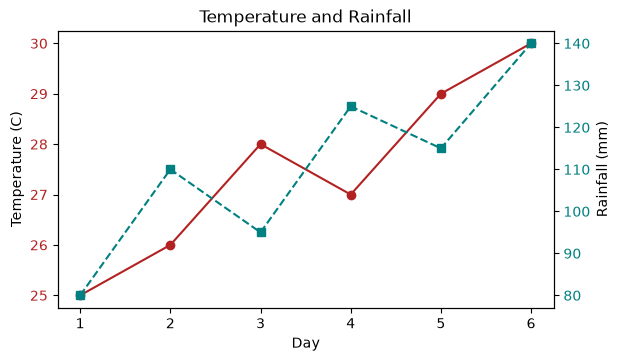

In [55]:
day = np.array([1, 2, 3, 4, 5, 6])
temperature = np.array([25, 26, 28, 27, 29, 30])
rainfall = np.array([80, 110, 95, 125, 115, 140])

fig, ax1 = plt.subplots(figsize=(6.4, 3.6))
ax2 = ax1.twinx()
ax1.plot(day, temperature, marker="o", color="firebrick")
ax2.plot(day, rainfall, marker="s", linestyle="--", color="teal")
ax1.set(title="Temperature and Rainfall", xlabel="Day", ylabel="Temperature (C)")
ax2.set_ylabel("Rainfall (mm)")
ax1.set_xticks(day)
ax1.tick_params(axis="y", labelcolor="firebrick")
ax2.tick_params(axis="y", labelcolor="teal")
plt.show()

---
## 3. Statistical Visualization

### 3.1 Preparing Simulated Statistical Data

Visualisasi statistik membantu melihat **perbandingan kelompok, distribusi, sebaran, dan hubungan antarvariabel**. Kita akan menggunakan data nilai dua kelas yang dibuat dengan bilangan acak. `default_rng(12)` membuat angka simulasi  konsisten saat dijalankan ulang.

In [12]:
rng = np.random.default_rng(12)
scores_a = np.clip(rng.normal(loc=78, scale=8, size=40), 0, 100)
scores_b = np.clip(rng.normal(loc=72, scale=10, size=40), 0, 100)
print("Class A: n =", len(scores_a), ", mean =", round(scores_a.mean(), 2))
print("Class B: n =", len(scores_b), ", mean =", round(scores_b.mean(), 2))

Class A: n = 40 , mean = 77.99
Class B: n = 40 , mean = 72.93


`np.clip()` membatasi nilai agar tetap berada pada rentang 0–100.

### 3.2 Creating Bar Charts

**Bar chart** digunakan untuk membandingkan **jumlah atau nilai ringkasan antar kategori**. Pada contoh ini, batang menunjukkan banyaknya mahasiswa simulasi yang memperoleh nilai minimal 75 pada tiap kelas.

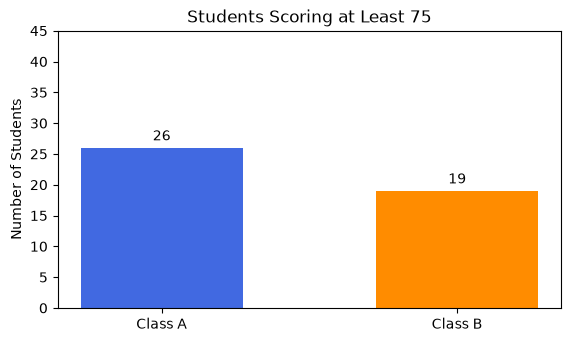

In [13]:
categories = ["Class A", "Class B"]
pass_counts = np.array([(scores_a >= 75).sum(), (scores_b >= 75).sum()])

fig, ax = plt.subplots(figsize=(6.5, 3.6))
bars = ax.bar(categories, pass_counts, color=["royalblue", "darkorange"], width=0.55)
ax.bar_label(bars, padding=3)
ax.set(title="Students Scoring at Least 75", ylabel="Number of Students")
ax.set_ylim(0, len(scores_a) + 5)
plt.show()

In [14]:
pass_counts

array([26, 19])

Kode ax.set_ylim(0, len(scores_a) + 5) mengatur batas sumbu Y mulai dari 0 hingga jumlah data `scores_a` ditambah 5, sehingga rentang sumbu Y menjadi 0–45.

### 3.3 Creating Stacked Bar Charts

**Stacked bar chart** menampilkan komposisi setiap kategori. Pada grafik berikut, bagian bawah adalah jumlah nilai ≥75, sedangkan bagian atas adalah nilai di bawah 75. Jumlah kedua segmen sama dengan ukuran kelas.

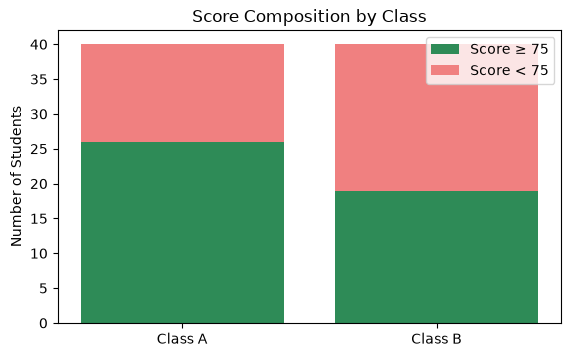

In [15]:
below_counts = np.array([(scores_a < 75).sum(), (scores_b < 75).sum()])

fig, ax = plt.subplots(figsize=(6.5, 3.8))

ax.bar(categories, pass_counts, label="Score ≥ 75", color="seagreen")
ax.bar(categories, below_counts, bottom=pass_counts, label="Score < 75", color="lightcoral")
ax.set(title="Score Composition by Class", ylabel="Number of Students")

ax.legend()
plt.show()

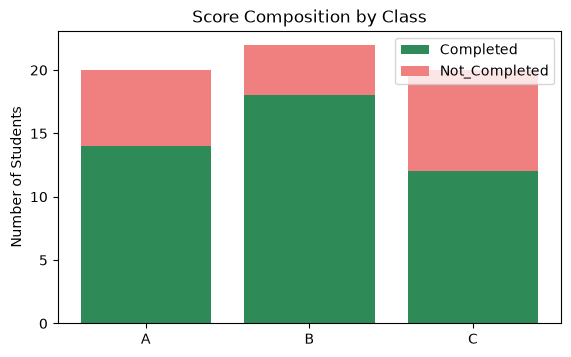

In [51]:
team = np.array(["A","B","C"])
completed = np.array([14,18,12])
not_completed = np.array([6,4,8])


fig, ax = plt.subplots(figsize=(6.5, 3.8))

ax.bar(team, completed, label="Completed", color="seagreen")
ax.bar(team, not_completed, bottom=completed, label="Not_Completed", color="lightcoral")
ax.set(title="Score Composition by Class", ylabel="Number of Students")

ax.legend()
plt.show()

In [16]:
below_counts

array([14, 21])

Kode bottom=pass_counts` menempatkan batang di atas data sebelumnya (stacked bar), `label` memberi keterangan, dan `color` mengatur warna batang.

### 3.4 Understanding Histograms

**Histogram** menggambarkan distribusi data numerik dengan membagi nilai ke dalam beberapa interval (*bins*). Berbeda dari bar chart kategori, batang histogram mewakili interval nilai yang berurutan. Mengubah `bins` dapat mengubah tingkat kerincian grafik.

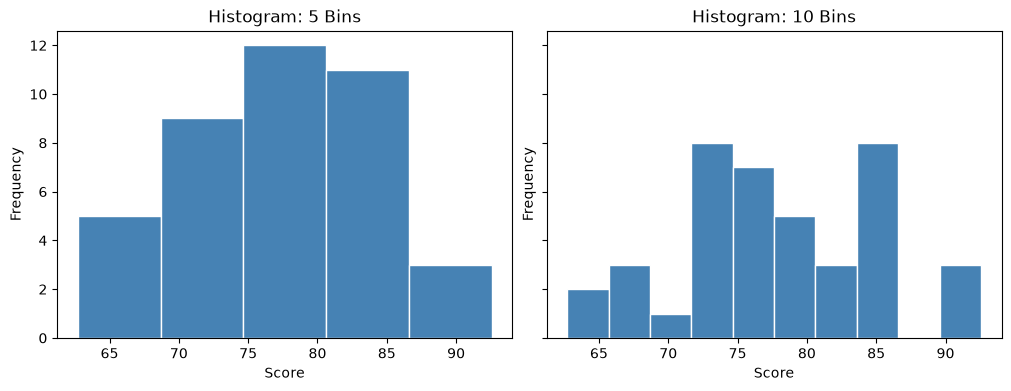

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True, layout="constrained")
for ax, n_bins in zip(axes, [5, 10]):
    ax.hist(scores_a, bins=n_bins, color="steelblue", edgecolor="white")
    ax.set(title=f"Histogram: {n_bins} Bins", xlabel="Score", ylabel="Frequency")
plt.show()

Kode  `sharey=True` menyamakan skala sumbu Y pada kedua grafik, `layout="constrained"` mengatur tata letak agar tidak saling bertumpuk

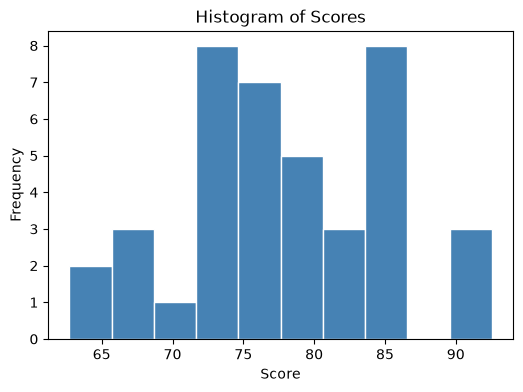

In [18]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(
    scores_a,
    bins=10,
    color="steelblue",
    edgecolor="white"
)
ax.set(
    title="Histogram of Scores",
    xlabel="Score",
    ylabel="Frequency"
)
plt.show()

### 3.5 Comparing Distributions with Boxplots

**Boxplot** merangkum median, kuartil, dan sebaran data. Garis di dalam kotak adalah **median**, batas kotak menunjukkan **Q1–Q3**, sedangkan titik di luar *whisker* dapat ditandai sebagai pencilan.

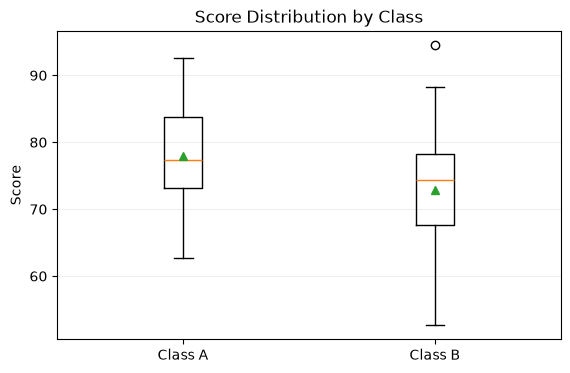

In [19]:
fig, ax = plt.subplots(figsize=(6.5, 4))
# segitiga adalah means jika showmeans true
ax.boxplot([scores_a, scores_b], showmeans=True)
ax.set_xticks([1, 2], categories)
ax.set(title="Score Distribution by Class", ylabel="Score")
ax.grid(axis="y", alpha=0.2)
plt.show()

### 3.6 Exploring Relationships with Scatter Plots

**Scatter plot** dipakai untuk melihat pola hubungan dua variabel numerik. Satu titik adalah satu pengamatan. Pada contoh simulasi ini, X merupakan jam belajar dan Y merupakan nilai ujian.

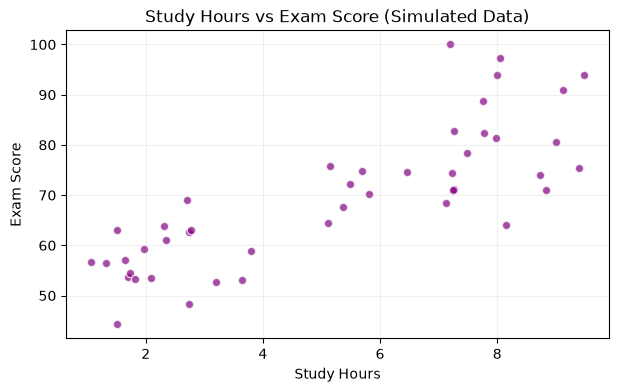

Pearson correlation: 0.81


In [20]:
# buat data baru
study_hours = rng.uniform(1, 10, size=45)
exam_scores = np.clip(48 + 4.3 * study_hours + rng.normal(0, 9, size=45), 0, 100)

fig, ax = plt.subplots(figsize=(7, 4))

ax.scatter(study_hours, exam_scores, color="purple", alpha=0.7, edgecolors="white")
ax.set(title="Study Hours vs Exam Score (Simulated Data)", xlabel="Study Hours", ylabel="Exam Score")
ax.grid(alpha=0.18)

plt.show()
print("Pearson correlation:", round(np.corrcoef(study_hours, exam_scores)[0, 1], 3))

---
## 4. Saving Figures

### 4.1 Choosing a Plot Style

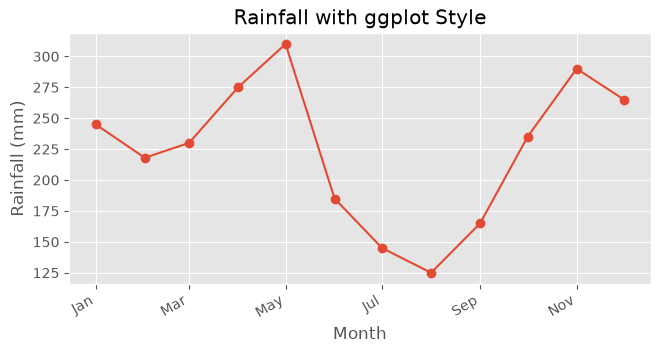

In [21]:
with plt.style.context("ggplot"):
    fig, ax = plt.subplots(figsize=(7.5, 3.7))
    ax.plot(weather.index, weather["Rainfall_mm"], marker="o")
    ax.set(title="Rainfall with ggplot Style", xlabel="Month", ylabel="Rainfall (mm)")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
    fig.autofmt_xdate()
    plt.show()

`with plt.style.context("ggplot")` menerapkan gaya tampilan grafik ggplot secara sementara. Pengaturan ini hanya berlaku di dalam blok `with` dan akan kembali ke gaya sebelumnya setelah blok selesai.

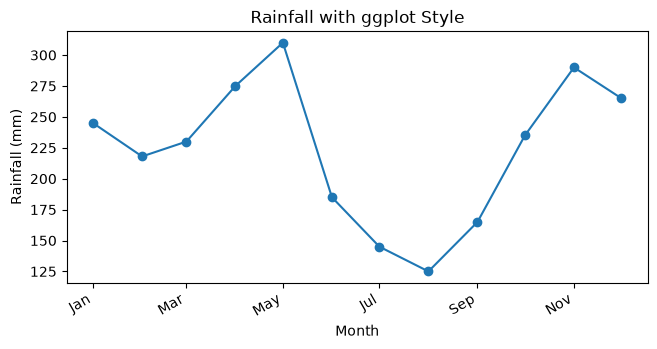

In [22]:
    fig, ax = plt.subplots(figsize=(7.5, 3.7))
    ax.plot(weather.index, weather["Rainfall_mm"], marker="o")
    ax.set(title="Rainfall with ggplot Style", xlabel="Month", ylabel="Rainfall (mm)")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
    fig.autofmt_xdate()
    plt.show()

### 4.2 Saving PNG, PDF, and SVG Files

Gunakan `fig.savefig()` untuk menyimpan gambar. **PNG** adalah gambar raster, sedangkan **PDF** dan **SVG** cocok untuk grafik berbasis vektor. `dpi=300` mengatur resolusi saat menyimpan PNG, dan `bbox_inches="tight"` membantu mengurangi bagian kosong atau label terpotong.

Kode berikut otomatis membuat folder `week12_figures` di lokasi notebook dijalankan.

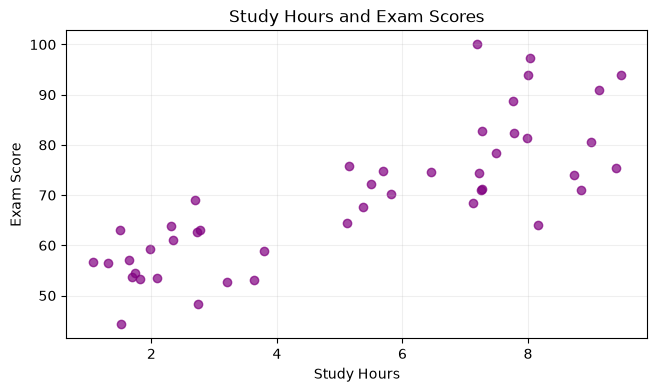

Saved to: /Users/muhammadmirzaapriansyah/Downloads/week12_figures


In [23]:
output_dir = Path("week12_figures")
output_dir.mkdir(exist_ok=True)

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.scatter(study_hours, exam_scores, alpha=0.7, color="purple")
ax.set(title="Study Hours and Exam Scores", xlabel="Study Hours", ylabel="Exam Score")
ax.grid(alpha=0.2)

fig.savefig(output_dir / "week12_scatter.png", dpi=300, bbox_inches="tight")
fig.savefig(output_dir / "week12_scatter.pdf", bbox_inches="tight")
fig.savefig(output_dir / "week12_scatter.svg", bbox_inches="tight")
plt.show()
print("Saved to:", output_dir.resolve())

### 4.3 Adjusting Figure Size and Resolution

`figsize=(8, 4)` menentukan ukuran gambar dalam **inci**, bukan piksel. Ketika disimpan sebagai PNG dengan `dpi=300`, ukuran nominal 8 × 4 inci setara dengan sekitar 2400 × 1200 piksel, sebelum penyesuaian `bbox_inches="tight"`.

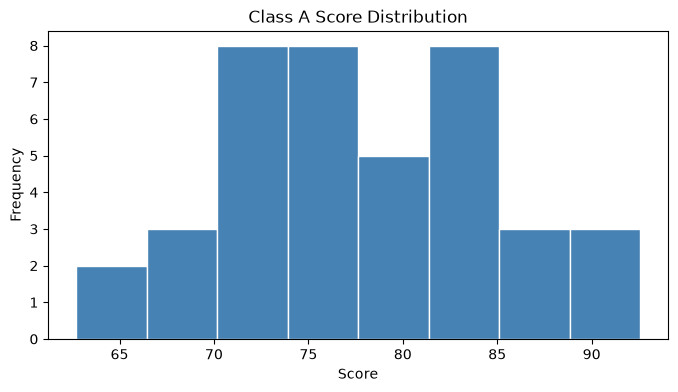

File: week12_figures/week12_histogram_300dpi.png
File size: 54.1 KB


In [24]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(scores_a, bins=8, edgecolor="white", color="steelblue")
ax.set(title="Class A Score Distribution", xlabel="Score", ylabel="Frequency")
file_path = output_dir / "week12_histogram_300dpi.png"
fig.savefig(file_path, dpi=300, bbox_inches="tight")
plt.show()
print("File:", file_path)
print("File size:", round(file_path.stat().st_size / 1024, 1), "KB")

### 4.4 Checking Saved Files

Sebelum menyerahkan hasil, pastikan file benar-benar tersimpan. Gunakan `Path.exists()` untuk memeriksa keberadaan file, lalu buka gambar jika perlu memeriksa apakah judul dan label terbaca.

In [25]:
for name in ["week12_scatter.png", "week12_scatter.pdf", "week12_scatter.svg",
             "week12_histogram_300dpi.png"]:
    path = output_dir / name
    print(f"{name}: {'Found' if path.exists() else 'Missing'}")

week12_scatter.png: Found
week12_scatter.pdf: Found
week12_scatter.svg: Found
week12_histogram_300dpi.png: Found


---
## 5. Independent Student Exercises


### Exercise 1 — Basic Line Plot

Gunakan data berikut:

```python
weeks = [1, 2, 3, 4, 5]
visitors = [120, 135, 128, 150, 165]
```

1. Buat grafik garis dengan `fig, ax = plt.subplots()` dan `ax.plot()`.
2. Tambahkan marker bulat, judul, serta label sumbu X dan Y dalam **bahasa Inggris**.
3. Sebutkan minggu dengan jumlah pengunjung tertinggi.

### Exercise 2 — Comparing Two Time Series

Gunakan data berikut (simulasi):

```python
dates = pd.date_range("2026-01-01", periods=6, freq="MS")
station_a = [180, 200, 190, 230, 210, 240]
station_b = [160, 170, 185, 205, 195, 220]
```

1. Buat **dua garis** dalam satu grafik dengan warna, `label`, dan `legend` berbeda.
2. Atur label tanggal supaya mudah dibaca.
3. Identifikasi bulan ketika kedua stasiun memiliki selisih terbesar.

### Exercise 3 — Bar Charts and Stacked Bars

Gunakan data kategori berikut:

```python
departments = ["A", "B", "C"]
completed = np.array([28, 35, 30])
not_completed = np.array([12, 5, 10])
```

1. Buat **bar chart** yang memperlihatkan jumlah `completed`.
2. Buat **stacked bar chart** menggunakan `bottom=completed`.
3. Beri judul, label sumbu, dan legenda yang jelas.

### Exercise 4 — Histogram and Boxplot

Gunakan kembali `scores_a` dan `scores_b` dari Section 3.

1. Buat histogram `scores_a` dengan `bins=6` dan `bins=12`.
2. Bandingkan bentuk histogram keduanya dalam satu kalimat.
3. Buat boxplot dua kelas dan bandingkan median secara visual.

### Exercise 5 — Scatter Plot
Gunakan kembali `study_hours`, `exam_scores`, `scores_a`, dan `scores_b`.

1. Buat scatter plot antara jam belajar dan nilai ujian.
2. Jelaskan apakah arah hubungan terlihat positif, negatif, atau tidak jelas.


### Exercise 6 — Saving a Publication-Ready Figure

1. Pilih salah satu grafik yang sudah dibuat.
2. Atur ukuran `figsize=(8, 4)` dan tambahkan judul serta label yang sesuai.
3. Simpan sebagai **PNG (300 dpi)** dan **PDF** dengan `bbox_inches="tight"`.
4. Pastikan kedua file berhasil dibuat dan jelaskan perbedaan kegunaannya.

### ✅ Jawaban Independent Student Exercises
Jawaban di bawah memakai variabel dari Section 3 (`scores_a`, `scores_b`, `study_hours`, `exam_scores`), jadi jalankan notebook dari atas.

## Exercise 1 — Basic Line Plot

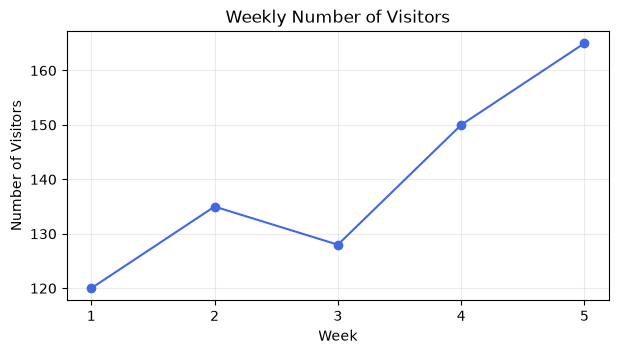

Minggu dengan pengunjung tertinggi: Minggu 5 (165 pengunjung)


In [26]:
weeks = [1, 2, 3, 4, 5]
visitors = [120, 135, 128, 150, 165]

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(weeks, visitors, marker="o", color="royalblue")
ax.set(title="Weekly Number of Visitors", xlabel="Week", ylabel="Number of Visitors")
ax.set_xticks(weeks)
ax.grid(alpha=0.25)
plt.show()

best_idx = int(np.argmax(visitors))
print(f"Minggu dengan pengunjung tertinggi: Minggu {weeks[best_idx]} ({visitors[best_idx]} pengunjung)")

**Jawaban:** Pengunjung tertinggi terjadi pada **minggu ke-5** dengan **165 pengunjung**.

## Exercise 2 — Comparing Two Time Series

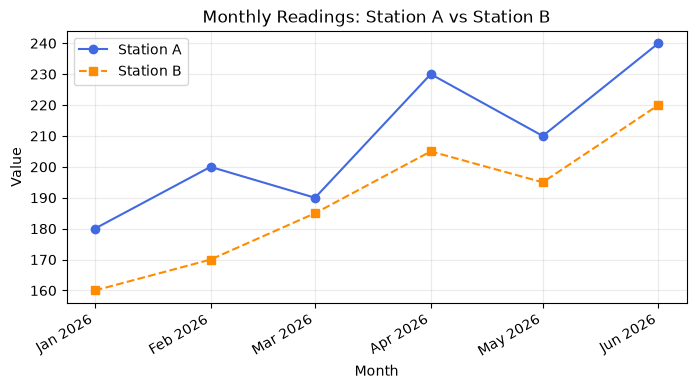

2026-01-01    20
2026-02-01    30
2026-03-01     5
2026-04-01    25
2026-05-01    15
2026-06-01    20
Freq: MS, dtype: int64
Selisih terbesar: February 2026 = 30


In [27]:
dates = pd.date_range("2026-01-01", periods=6, freq="MS")
station_a = [180, 200, 190, 230, 210, 240]
station_b = [160, 170, 185, 205, 195, 220]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(dates, station_a, color="royalblue", marker="o", label="Station A")
ax.plot(dates, station_b, color="darkorange", marker="s", linestyle="--", label="Station B")
ax.set(title="Monthly Readings: Station A vs Station B", xlabel="Month", ylabel="Value")
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.legend()
ax.grid(alpha=0.25)
fig.autofmt_xdate()
plt.show()

diff = pd.Series(np.abs(np.array(station_a) - np.array(station_b)), index=dates)
print(diff)
print("Selisih terbesar:", diff.idxmax().strftime("%B %Y"), "=", diff.max())

**Jawaban:** Selisih terbesar terjadi pada **Februari 2026** (200 − 170 = **30**).

## Exercise 3 — Bar Charts and Stacked Bars

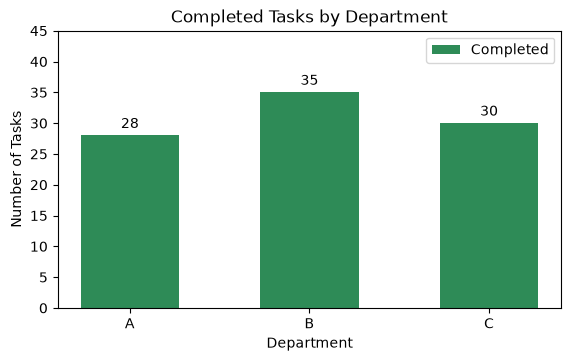

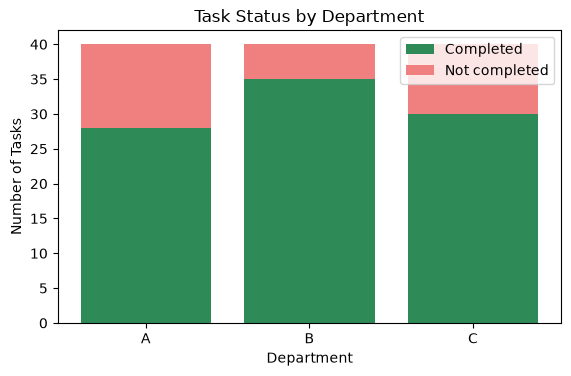

In [28]:
departments = ["A", "B", "C"]
completed = np.array([28, 35, 30])
not_completed = np.array([12, 5, 10])

# 1. Bar chart
fig, ax = plt.subplots(figsize=(6.5, 3.6))
bars = ax.bar(departments, completed, color="seagreen", width=0.55, label="Completed")
ax.bar_label(bars, padding=3)
ax.set(title="Completed Tasks by Department", xlabel="Department", ylabel="Number of Tasks")
ax.set_ylim(0, 45)
ax.legend()
plt.show()

# 2. Stacked bar chart
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.bar(departments, completed, label="Completed", color="seagreen")
ax.bar(departments, not_completed, bottom=completed, label="Not completed", color="lightcoral")
ax.set(title="Task Status by Department", xlabel="Department", ylabel="Number of Tasks")
ax.legend()
plt.show()

**Catatan:** Total tugas tiap departemen sama, yaitu 40 (A: 28+12, B: 35+5, C: 30+10). Departemen B memiliki jumlah `completed` tertinggi.

## Exercise 4 — Histogram and Boxplot

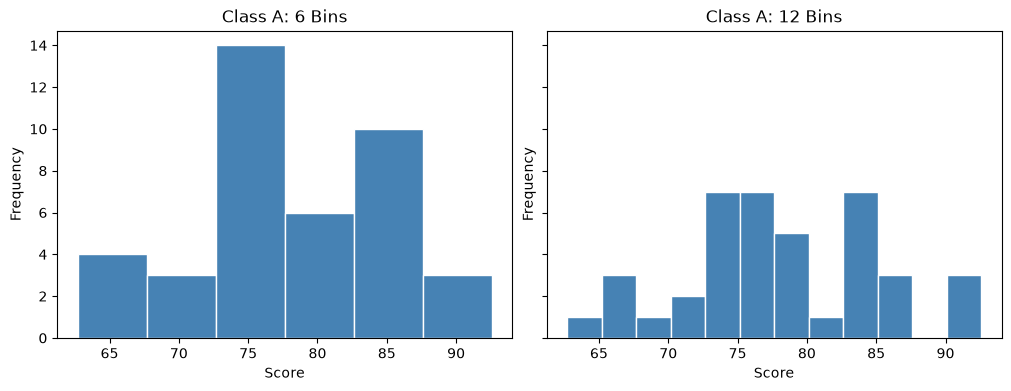

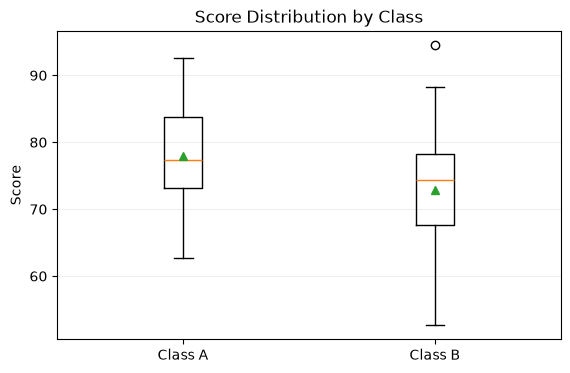

Median Class A: 77.34
Median Class B: 74.34


In [29]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True, layout="constrained")
for ax, n_bins in zip(axes, [6, 12]):
    ax.hist(scores_a, bins=n_bins, color="steelblue", edgecolor="white")
    ax.set(title=f"Class A: {n_bins} Bins", xlabel="Score", ylabel="Frequency")
plt.show()

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.boxplot([scores_a, scores_b], showmeans=True)
ax.set_xticks([1, 2], ["Class A", "Class B"])
ax.set(title="Score Distribution by Class", ylabel="Score")
ax.grid(axis="y", alpha=0.2)
plt.show()

print("Median Class A:", round(np.median(scores_a), 2))
print("Median Class B:", round(np.median(scores_b), 2))

**Jawaban:**
2. Histogram dengan `bins=6` tampak lebih halus dan menyederhanakan bentuk distribusi (puncak jelas di sekitar nilai 75–80), sedangkan `bins=12` lebih rinci sehingga bentuknya bergerigi dan menampilkan variasi antar-interval.
3. Median Class A (≈ 77,3) lebih tinggi daripada Class B (≈ 74,3), dan kotak Class B lebih lebar, artinya sebaran nilainya lebih besar.

## Exercise 5 — Scatter Plot

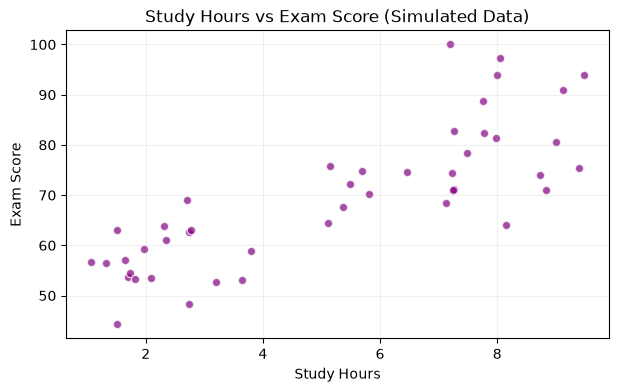

Pearson correlation: 0.81


In [30]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(study_hours, exam_scores, color="purple", alpha=0.7, edgecolors="white")
ax.set(title="Study Hours vs Exam Score (Simulated Data)", xlabel="Study Hours", ylabel="Exam Score")
ax.grid(alpha=0.18)
plt.show()
print("Pearson correlation:", round(np.corrcoef(study_hours, exam_scores)[0, 1], 3))

**Jawaban:** Arah hubungan **positif**: semakin banyak jam belajar, nilai ujian cenderung naik (korelasi Pearson ≈ 0,81). Namun korelasi tidak membuktikan hubungan sebab-akibat.

## Exercise 6 — Saving a Publication-Ready Figure

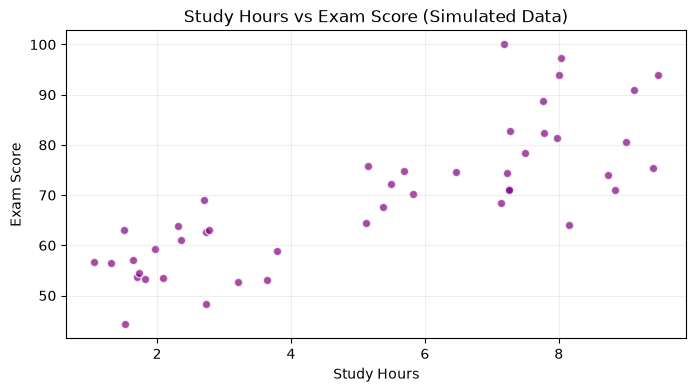

exercise6_scatter.png: Found (96.4 KB)
exercise6_scatter.pdf: Found (13.7 KB)


In [31]:
output_dir = Path("week12_figures")
output_dir.mkdir(exist_ok=True)

fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(study_hours, exam_scores, color="purple", alpha=0.7, edgecolors="white")
ax.set(title="Study Hours vs Exam Score (Simulated Data)", xlabel="Study Hours", ylabel="Exam Score")
ax.grid(alpha=0.2)

fig.savefig(output_dir / "exercise6_scatter.png", dpi=300, bbox_inches="tight")
fig.savefig(output_dir / "exercise6_scatter.pdf", bbox_inches="tight")
plt.show()

for name in ["exercise6_scatter.png", "exercise6_scatter.pdf"]:
    p = output_dir / name
    print(f"{name}: {'Found' if p.exists() else 'Missing'}", f"({p.stat().st_size/1024:.1f} KB)" if p.exists() else "")

**Perbedaan kegunaan:**
- **PNG (300 dpi)** adalah gambar raster berbasis piksel. Cocok untuk slide, laporan Word, dan web. Kualitas bergantung pada `dpi`, dan gambar bisa pecah jika diperbesar berlebihan.
- **PDF** adalah format vektor. Garis dan teks tetap tajam di ukuran berapa pun, sehingga cocok untuk jurnal, skripsi, dan cetak (LaTeX).

---
## 6. Meeting Summary and Self-Assessment

### Essential Concepts

- **Matplotlib** membuat grafik menggunakan objek `Figure` dan `Axes`.
- **`ax.plot()`** digunakan untuk grafik garis, termasuk data **time series**.
- **`mdates`** membantu mengatur tampilan tanggal, sedangkan **`annotate()`** menandai pengamatan penting.
- **`ax.bar()`** membandingkan kategori; **`ax.hist()`** menggambarkan distribusi nilai numerik.
- **`ax.boxplot()`** merangkum median dan sebaran; **`ax.scatter()`** menunjukkan pola hubungan.
- **`fig.savefig()`** menyimpan grafik; **`dpi`** terutama relevan untuk keluaran raster seperti PNG.

### Quick Self-Assessment

1. Apa perbedaan `Figure` dan `Axes`?
2. Metode apa yang dipakai untuk menggambar dua garis pada area grafik yang sama?
3. Grafik apa yang paling sesuai untuk melihat tren bulanan?
4. Apa perbedaan bar chart dan histogram?
5. Apa arti garis di dalam kotak pada boxplot?
6. Apakah scatter plot yang naik membuktikan hubungan sebab-akibat?
7. Metode dan parameter apa yang dipakai untuk menyimpan PNG beresolusi 300 dpi?

**Answers:** (1) `Figure` adalah keseluruhan gambar, `Axes` adalah area plot; (2) panggil `ax.plot()` dua kali dengan data berbeda; (3) line plot; (4) bar chart membandingkan kategori, histogram membagi angka ke dalam interval; (5) median; (6) tidak; (7) `fig.savefig("file.png", dpi=300)`.

### Source Materials and References

**Course materials provided by the lecturer:**

- Rokem, A. (DataCamp). *Introduction to Data Visualization with Matplotlib — Introduction* (uploaded lecture PDF).
- Rokem, A. (DataCamp). *Plotting Time-Series Data* (uploaded lecture PDF).
- Rokem, A. (DataCamp). *Statistical Visualization* (uploaded lecture PDF).
- Rokem, A. (DataCamp). *Saving Figures* (uploaded lecture PDF).

**Official documentation and checkable online resources:**

- [Matplotlib Development Team. *Quick Start Guide*.](https://matplotlib.org/stable/users/explain/quick_start.html)
- [Matplotlib Development Team. *Date Tick Labels*.](https://matplotlib.org/stable/gallery/ticks/date.html)
- [Matplotlib Development Team. *Annotations*.](https://matplotlib.org/stable/users/explain/text/annotations.html)
- [Matplotlib Development Team. *Statistics Gallery*.](https://matplotlib.org/stable/gallery/statistics/index.html)
- [Matplotlib Development Team. *Plot Types*.](https://matplotlib.org/stable/plot_types/)
- [Matplotlib Development Team. *Figure.savefig*.](https://matplotlib.org/stable/api/_as_gen/matplotlib.figure.Figure.savefig.html)
- [Matplotlib Development Team. *Style Sheets Reference*.](https://matplotlib.org/stable/gallery/style_sheets/style_sheets_reference.html)
- [DataCamp. *Introduction to Data Visualization with Matplotlib*.](https://www.datacamp.com/courses/introduction-to-data-visualization-with-matplotlib)

### ✅ Jawaban Quick Self-Assessment

1. **`Figure` vs `Axes`:** `Figure` adalah keseluruhan gambar (kanvas), sedangkan `Axes` adalah area tempat data digambar, lengkap dengan sumbu, judul, dan label. Satu `Figure` dapat berisi satu atau banyak `Axes` (subplot).
2. **Dua garis pada area grafik yang sama:** panggil `ax.plot()` dua kali pada `ax` yang sama dengan data berbeda, tambahkan `label=...` lalu `ax.legend()`.
3. **Grafik untuk tren bulanan:** line plot (`ax.plot()`), karena menghubungkan pengamatan berurutan sehingga perubahan dari waktu ke waktu terlihat jelas.
4. **Bar chart vs histogram:** bar chart membandingkan nilai/jumlah antar kategori; histogram membagi data numerik ke dalam interval berurutan (*bins*) untuk menunjukkan distribusi.
5. **Garis di dalam kotak boxplot:** **median**. Batas kotak adalah Q1 dan Q3.
6. **Scatter plot naik = sebab-akibat?** Tidak. Scatter plot hanya menunjukkan asosiasi; sebab-akibat tidak dapat disimpulkan dari pola grafik saja karena bisa ada faktor lain.
7. **Menyimpan PNG 300 dpi:** `fig.savefig("file.png", dpi=300, bbox_inches="tight")`.

---
## 7. Google Colab

### Langkah-Langkah Dasar Menggunakan Google Colab

1. **Buka Google Colab**  
   Kunjungi [colab.research.google.com](https://colab.research.google.com) dan *login* dengan akun Google Anda.

2. **Buat *Notebook* Baru**  
   Klik **New Notebook** (atau buka *file* `.ipynb` yang sudah ada dari Google Drive/GitHub).

3. **Tulis Kode atau Teks**  
   * Klik **+ Code** untuk menambahkan sel kode Python, lalu jalankan dengan tombol *Play* (`▶`) atau tekan `Shift + Enter`.
   * Klik **+ Text** untuk menambahkan catatan/dokumentasi berformat Markdown.

4. **Atur *Runtime* (Opsional)**  
   Klik menu **Runtime > Change runtime type** untuk memilih *hardware* (`CPU`, `T4 GPU`, atau `TPU`) sesuai kebutuhan komputasi.

5. **Hubungkan ke Google Drive (Opsional)**  
   Jalankan kode berikut di sel kode untuk mengakses *file* di Drive:
   ```python
   from google.colab import drive
   drive.mount('/content/drive')
   
   

6. **Simpan & Bagikan**: Notebook otomatis tersimpan di folder Colab Notebooks pada Google Drive Anda. Gunakan File > Save a copy in Drive atau tombol Share untuk membagikan akses.

### Mengunggah Dataset ke Google Colab



* **Unggah langsung dari komputer** (*file* kecil):
  ```python
  from google.colab import files
  uploaded = files.upload()
 
  Baca file (misalnya data.csv) menggunakan pandas:
    ```python
  import pandas as pd
  df = pd.read_csv("data.csv")

  

  
* **Baca dari Google Drive** (file berulang atau berukuran besar):
  Setelah menjalankan drive.mount('/content/drive'), muat data langsung dari path Drive:
  ```python
  import pandas as pd
  df = pd.read_csv("/content/drive/MyDrive/folder_anda/data.csv")

  
Cara paling cepat cari path tanpa kode: 
Setelah menjalankan drive.mount('/content/drive')
Klik panah kecil (▸) di sebelah kiri folder content untuk membukanya.
Di dalam content, buka folder drive > MyDrive, lalu cari folder dan file dataset Anda.
klik ikon Folder (📁) di bilah kiri Colab setelah mount Drive, navigasikan ke file tujuan, lalu klik ikon titik tiga (⋮) > Copy path.

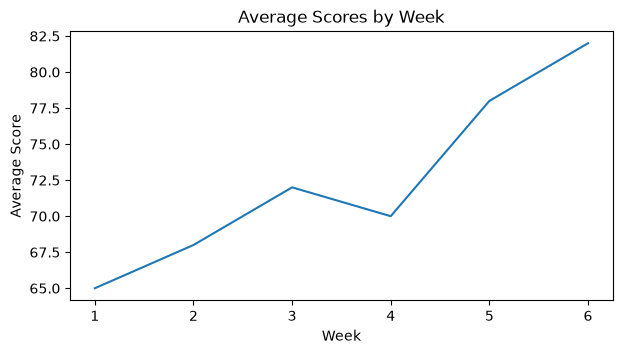

In [32]:
weeks = np.array([1, 2, 3, 4, 5, 6])
average_scores = np.array([65, 68, 72, 70, 78, 82])

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(weeks, average_scores)
ax.set_title("Average Scores by Week")
ax.set_xlabel("Week")
ax.set_ylabel("Average Score")
ax.set_xticks(weeks)
plt.show()